In [11]:

import os
import copy
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)


In [2]:
data=pd.read_csv('hourly_data.csv')

In [3]:
data.head()

,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3,is_weekend,hour_sin,hour_cos,day_sin,day_cos
0,4.222889,0.229000,234.643889,18.100000,0.0,19.0,607.0,1,-0.965926,-2.588190e-01,-0.974928,-0.222521
1,3.632200,0.080033,234.580167,15.600000,0.0,403.0,1012.0,1,-1.000000,-1.836970e-16,-0.974928,-0.222521
2,3.400233,0.085233,233.232500,14.503333,0.0,86.0,1001.0,1,-0.965926,2.588190e-01,-0.974928,-0.222521
3,3.268567,0.075100,234.071500,13.916667,0.0,0.0,1007.0,1,-0.866025,5.000000e-01,-0.974928,-0.222521
4,3.056467,0.076667,237.158667,13.046667,0.0,25.0,1033.0,1,-0.707107,7.071068e-01,-0.974928,-0.222521


In [6]:

n = len(data)

train_end = int(n * 0.70)
val_end = int(n * 0.85)

train_df =data.iloc[:train_end].copy()
val_df =data.iloc[train_end:val_end].copy()
test_df = data.iloc[val_end:].copy()

print("Training:", train_df.shape)
print("Validation:", val_df.shape)
print("Testing:", test_df.shape)


Training: (23933, 12)
Validation: (5128, 12)
Testing: (5129, 12)


In [9]:
from sklearn.preprocessing import StandardScaler
target_col = "Global_active_power"

feature_cols = data.columns.tolist()

# Fit feature scaler only on training data
feature_scaler = StandardScaler()

feature_scaler.fit(train_df[feature_cols])

# Transform all data using training statistics
scaled_features = feature_scaler.transform(
    data[feature_cols]
)

# Separate target scaler
target_scaler = StandardScaler()

target_scaler.fit(train_df[[target_col]])

scaled_target = target_scaler.transform(
    data[[target_col]]
)

print("Number of input features:", len(feature_cols))


Number of input features: 12


In [10]:

LOOKBACK = 24

X_all = []
y_all = []
target_indices = []

for i in range(LOOKBACK, len(data)):

    X_all.append(
        scaled_features[i-LOOKBACK:i]
    )

    y_all.append(
        scaled_target[i, 0]
    )

    target_indices.append(i)

X_all = np.asarray(X_all, dtype=np.float32)
y_all = np.asarray(y_all, dtype=np.float32)

target_indices = np.asarray(target_indices)

train_mask = target_indices < train_end

val_mask = (
    (target_indices >= train_end) &
    (target_indices < val_end)
)

test_mask = target_indices >= val_end

X_train, y_train = X_all[train_mask], y_all[train_mask]
X_val, y_val = X_all[val_mask], y_all[val_mask]
X_test, y_test = X_all[test_mask], y_all[test_mask]

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("X_val:", X_val.shape)
print("y_val:", y_val.shape)

print("X_test:", X_test.shape)
print("y_test:", y_test.shape)


X_train: (23909, 24, 12)
y_train: (23909,)
X_val: (5128, 24, 12)
y_val: (5128,)
X_test: (5129, 24, 12)
y_test: (5129,)


In [12]:

class ElectricityDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(
            X,
            dtype=torch.float32
        )
        self.y = torch.tensor(
            y,
            dtype=torch.float32
        ).unsqueeze(1)
    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):

        return self.X[idx], self.y[idx]


In [13]:
BATCH_SIZE = 64
train_dataset = ElectricityDataset(X_train, y_train)
val_dataset = ElectricityDataset(X_val, y_val)
test_dataset = ElectricityDataset(X_test, y_test)
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    pin_memory=torch.cuda.is_available()
)
val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    pin_memory=torch.cuda.is_available()
)
test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    pin_memory=torch.cuda.is_available()
)
print("Training batches:", len(train_loader))


Training batches: 374


In [14]:

class LSTMModel(nn.Module):

    def __init__(
        self,
        input_size,
        hidden_size=64,
        num_layers=2,
        dropout=0.2
    ):

        super().__init__()

        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout if num_layers > 1 else 0
        )

        self.fc = nn.Sequential(
            nn.Linear(hidden_size, 32),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(32, 1)
        )

    def forward(self, x):

        output, (hidden, cell) = self.lstm(x)

        # Use the last time step's output
        last_output = output[:, -1, :]

        prediction = self.fc(last_output)

        return prediction


In [16]:
device='cuda' if torch.cuda.is_available() else 'cpu'
model = LSTMModel(
    input_size=len(feature_cols),
    hidden_size=64,
    num_layers=2,
    dropout=0.2
).to(device)

print(model)

total_params = sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
)

print("Trainable parameters:", total_params)


LSTMModel(
  (lstm): LSTM(12, 64, num_layers=2, batch_first=True, dropout=0.2)
  (fc): Sequential(
    (0): Linear(in_features=64, out_features=32, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=32, out_features=1, bias=True)
  )
)
Trainable parameters: 55361


In [17]:

criterion = nn.MSELoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001,
    weight_decay=1e-5
)

EPOCHS = 30
PATIENCE = 5

best_val_loss = float("inf")
patience_counter = 0

history = {
    "train_loss": [],
    "val_loss": []
}


In [18]:
for epoch in range(EPOCHS):
    model.train()
    train_loss = 0.0
    for X_batch, y_batch in train_loader:

        X_batch = X_batch.to(device, non_blocking=True)
        y_batch = y_batch.to(device, non_blocking=True)

        optimizer.zero_grad()

        predictions = model(X_batch)

        loss = criterion(predictions, y_batch)

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0
        )

        optimizer.step()

        train_loss += loss.item() * len(X_batch)

    train_loss /= len(train_dataset)

    model.eval()
    val_loss = 0.0
    with torch.no_grad():

        for X_batch, y_batch in val_loader:

            X_batch = X_batch.to(device, non_blocking=True)
            y_batch = y_batch.to(device, non_blocking=True)

            predictions = model(X_batch)

            loss = criterion(predictions, y_batch)

            val_loss += loss.item() * len(X_batch)

    val_loss /= len(val_dataset)

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)

    print(
        f"Epoch [{epoch+1}/{EPOCHS}] "
        f"Train Loss: {train_loss:.5f} "
        f"Val Loss: {val_loss:.5f}"
    )
    if val_loss < best_val_loss:

        best_val_loss = val_loss

        best_model_state = copy.deepcopy(
            model.state_dict()
        )

        patience_counter = 0

    else:

        patience_counter += 1

    if patience_counter >= PATIENCE:

        print("Early stopping triggered.")
        break

model.load_state_dict(best_model_state)

print("Training complete!")


Epoch [1/30] Train Loss: 0.50404 Val Loss: 0.36204
Epoch [2/30] Train Loss: 0.38339 Val Loss: 0.33584
Epoch [3/30] Train Loss: 0.36672 Val Loss: 0.32846
Epoch [4/30] Train Loss: 0.35430 Val Loss: 0.32845
Epoch [5/30] Train Loss: 0.35025 Val Loss: 0.33462
Epoch [6/30] Train Loss: 0.34774 Val Loss: 0.32961
Epoch [7/30] Train Loss: 0.34210 Val Loss: 0.32273
Epoch [8/30] Train Loss: 0.33626 Val Loss: 0.32174
Epoch [9/30] Train Loss: 0.33567 Val Loss: 0.32524
Epoch [10/30] Train Loss: 0.33275 Val Loss: 0.32280
Epoch [11/30] Train Loss: 0.32573 Val Loss: 0.32450
Epoch [12/30] Train Loss: 0.32266 Val Loss: 0.32703
Epoch [13/30] Train Loss: 0.32380 Val Loss: 0.32144
Epoch [14/30] Train Loss: 0.31813 Val Loss: 0.32334
Epoch [15/30] Train Loss: 0.31502 Val Loss: 0.32362
Epoch [16/30] Train Loss: 0.31068 Val Loss: 0.32179
Epoch [17/30] Train Loss: 0.30625 Val Loss: 0.31910
Epoch [18/30] Train Loss: 0.30405 Val Loss: 0.31761
Epoch [19/30] Train Loss: 0.30030 Val Loss: 0.31664
Epoch [20/30] Train L

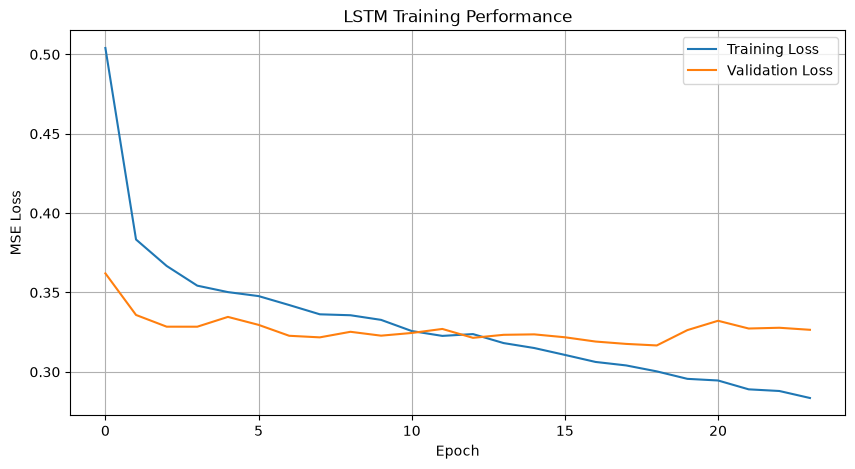

In [19]:

plt.figure(figsize=(10, 5))

plt.plot(history["train_loss"], label="Training Loss")
plt.plot(history["val_loss"], label="Validation Loss")

plt.title("LSTM Training Performance")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")

plt.legend()
plt.grid(True)
plt.show()


In [20]:

model.eval()

predictions = []
actuals = []

with torch.no_grad():

    for X_batch, y_batch in test_loader:

        X_batch = X_batch.to(device)

        pred = model(X_batch)

        predictions.extend(
            pred.cpu().numpy().flatten()
        )

        actuals.extend(
            y_batch.numpy().flatten()
        )

predictions = np.array(predictions).reshape(-1, 1)
actuals = np.array(actuals).reshape(-1, 1)

# Convert predictions back to kW
predictions_original = target_scaler.inverse_transform(
    predictions
)

actuals_original = target_scaler.inverse_transform(
    actuals
)


In [21]:

mae = mean_absolute_error(
    actuals_original,
    predictions_original
)

rmse = np.sqrt(
    mean_squared_error(
        actuals_original,
        predictions_original
    )
)

r2 = r2_score(
    actuals_original,
    predictions_original
)

print("Test Results")
print("----------------------")
print(f"MAE:  {mae:.4f} kW")
print(f"RMSE: {rmse:.4f} kW")
print(f"R2:   {r2:.4f}")


Test Results
----------------------
MAE:  0.3148 kW
RMSE: 0.4583 kW
R2:   0.5828


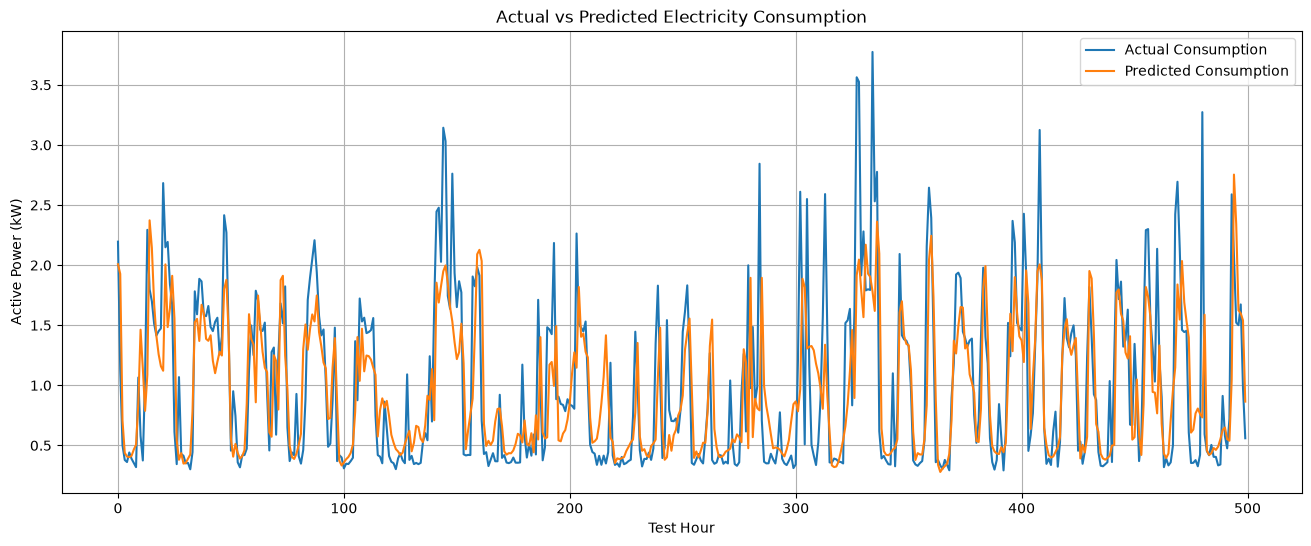

In [22]:

plt.figure(figsize=(16, 6))

plt.plot(
    actuals_original[:500],
    label="Actual Consumption"
)

plt.plot(
    predictions_original[:500],
    label="Predicted Consumption"
)

plt.title("Actual vs Predicted Electricity Consumption")
plt.xlabel("Test Hour")
plt.ylabel("Active Power (kW)")

plt.legend()
plt.grid(True)
plt.show()


In [23]:

target_idx = feature_cols.index(target_col)

# Last observed active power in each input sequence
baseline_scaled = X_test[:, -1, target_idx]

baseline_original = target_scaler.inverse_transform(
    baseline_scaled.reshape(-1, 1)
)

baseline_mae = mean_absolute_error(
    actuals_original,
    baseline_original
)

baseline_rmse = np.sqrt(
    mean_squared_error(
        actuals_original,
        baseline_original
    )
)

print("Persistence Baseline")
print("MAE:", baseline_mae)
print("RMSE:", baseline_rmse)

print("\nLSTM")
print("MAE:", mae)
print("RMSE:", rmse)


Persistence Baseline
MAE: 0.3856293559074402
RMSE: 0.5838905182501243

LSTM
MAE: 0.3147828280925751
RMSE: 0.45834326913930246


In [24]:

checkpoint = {
    "model_state_dict": model.state_dict(),

    "input_size": len(feature_cols),
    "hidden_size": 64,
    "num_layers": 2,
    "dropout": 0.2,

    "lookback": LOOKBACK,
    "feature_cols": feature_cols,
    "target_col": target_col,

    "feature_mean": feature_scaler.mean_,
    "feature_scale": feature_scaler.scale_,

    "target_mean": target_scaler.mean_,
    "target_scale": target_scaler.scale_
}

torch.save(
    checkpoint,
    "smartgrid_lstm.pth"
)

print("Model saved successfully!")


Model saved successfully!
